## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

## Data Preprocessing

In [2]:
raw_data = pd.read_csv('energy_weather_data.csv')
# Drop columns you do not need
clean_data = raw_data.drop(['AT_price_day_ahead', 'AT_wind_onshore_generation_actual','AT_load_actual_entsoe_transparency','AT_load_forecast_entsoe_transparency'], axis=1)



# Drop rows where target is NaN
newdata = clean_data.dropna(subset=["AT_solar_generation_actual"])
# NaN and info check
nan_counts = newdata.isna().sum()
print(nan_counts)
print(newdata.info())


datetime                      0
AT_solar_generation_actual    0
temperature_2m                0
relative_humidity_2m          0
dew_point_2m                  0
apparent_temperature          0
precipitation                 0
rain                          0
snowfall                      0
cloud_cover                   0
cloud_cover_low               0
cloud_cover_mid               0
cloud_cover_high              0
wind_speed_10m                0
wind_direction_10m            0
wind_gusts_10m                0
surface_pressure              0
shortwave_radiation           0
direct_radiation              0
diffuse_radiation             0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 43800 entries, 0 to 43847
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   datetime                    43800 non-null  object 
 1   AT_solar_generation_actual  43800 non-null  float64
 2   temperatur

In [3]:
newdata['datetime'] = pd.to_datetime(newdata['datetime'], dayfirst=True, errors='coerce')
newdata = newdata.sort_values('datetime')

numeric_newdata = newdata.select_dtypes(include=['float64', 'int64'])
corr = numeric_newdata.corr()

newdata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43800 entries, 0 to 43847
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   datetime                    43800 non-null  datetime64[ns]
 1   AT_solar_generation_actual  43800 non-null  float64       
 2   temperature_2m              43800 non-null  float64       
 3   relative_humidity_2m        43800 non-null  int64         
 4   dew_point_2m                43800 non-null  float64       
 5   apparent_temperature        43800 non-null  float64       
 6   precipitation               43800 non-null  float64       
 7   rain                        43800 non-null  float64       
 8   snowfall                    43800 non-null  float64       
 9   cloud_cover                 43800 non-null  int64         
 10  cloud_cover_low             43800 non-null  int64         
 11  cloud_cover_mid             43800 non-null  int64         


C:\Users\DELL\AppData\Local\Temp\ipykernel_17188\3392991471.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  newdata['datetime'] = pd.to_datetime(newdata['datetime'], dayfirst=True, errors='coerce')


## Colleration matrix

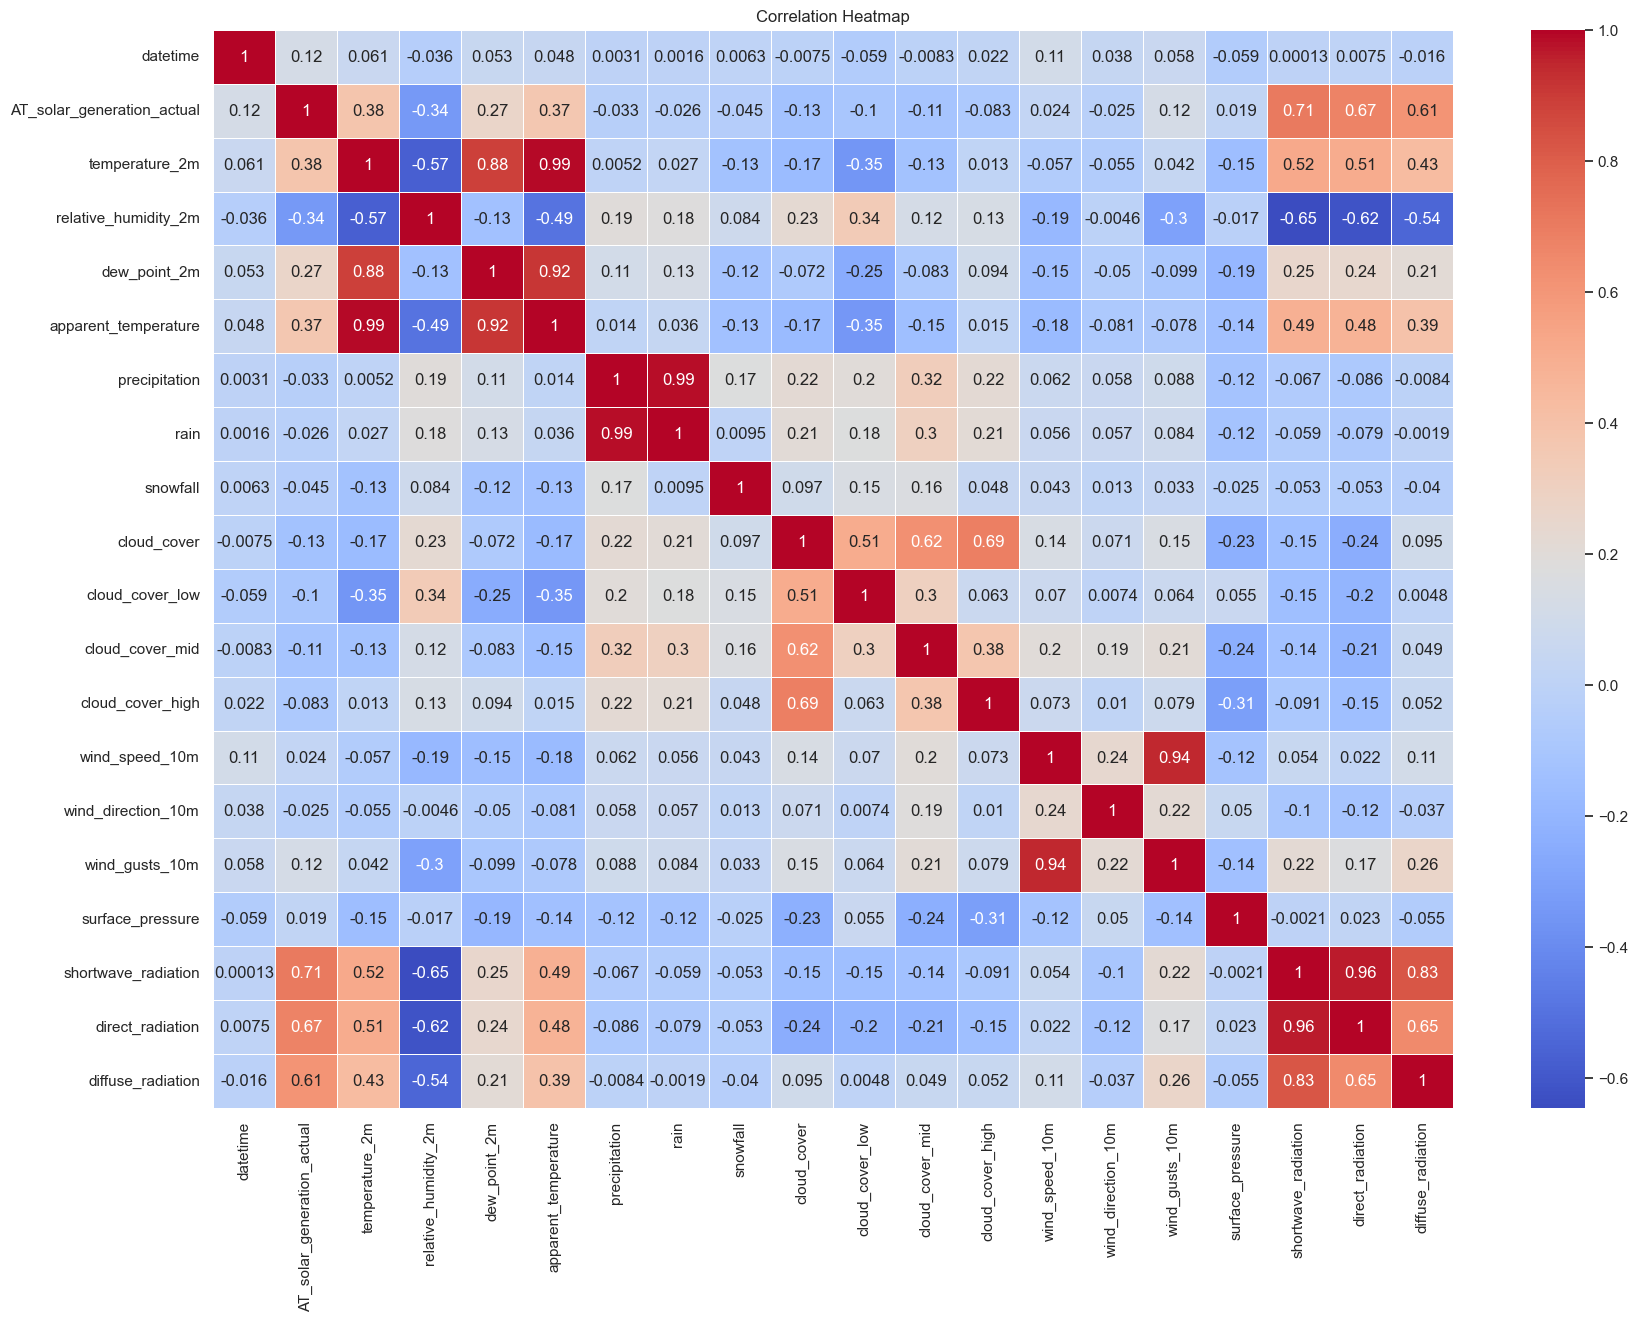

In [5]:
corr = newdata.corr()


plt.figure(figsize=(20, 14))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

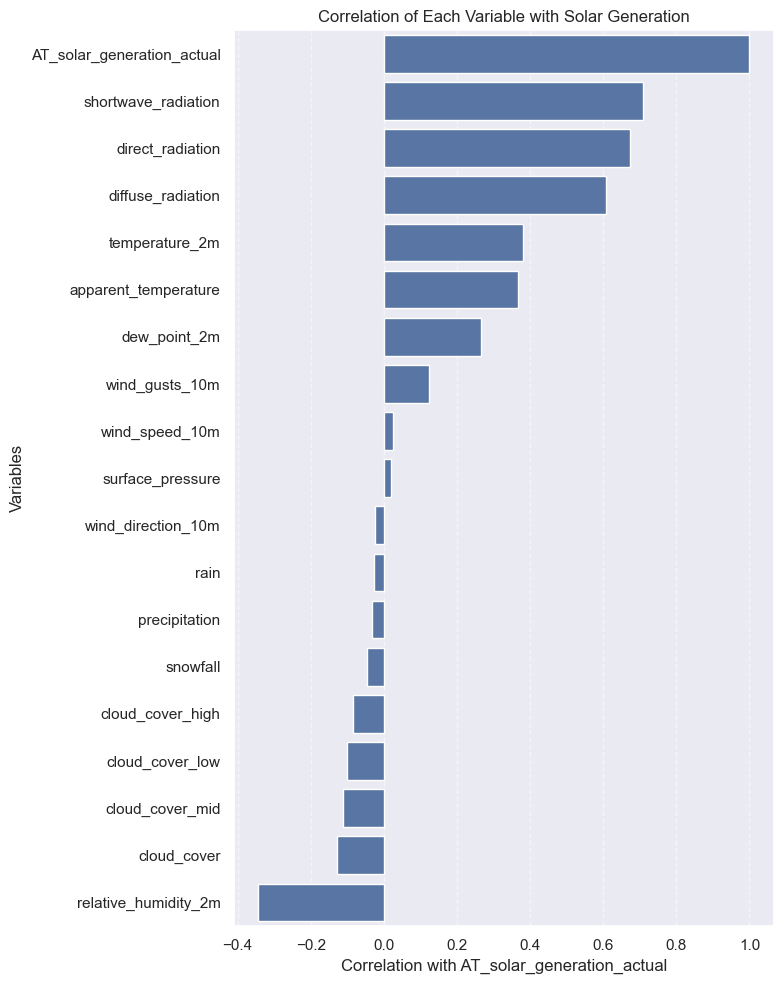

AT_solar_generation_actual    1.000000
shortwave_radiation           0.710037
direct_radiation              0.674285
diffuse_radiation             0.608568
temperature_2m                0.380039
apparent_temperature          0.368300
dew_point_2m                  0.266302
wind_gusts_10m                0.123588
wind_speed_10m                0.024472
surface_pressure              0.018674
wind_direction_10m           -0.025181
rain                         -0.025770
precipitation                -0.032636
snowfall                     -0.045301
cloud_cover_high             -0.083252
cloud_cover_low              -0.101271
cloud_cover_mid              -0.112657
cloud_cover                  -0.129076
relative_humidity_2m         -0.343148
Name: AT_solar_generation_actual, dtype: float64

In [6]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("plots/Corr", exist_ok=True)

target = "AT_solar_generation_actual"

# Safer correlation (handles non-numeric columns in newer pandas)
corr = newdata.corr(numeric_only=True)

corr_to_target = corr[target].sort_values(ascending=False)

plt.figure(figsize=(8, 10))
sns.barplot(x=corr_to_target.values, y=corr_to_target.index, orient='h')
plt.xlabel(f"Correlation with {target}")
plt.ylabel("Variables")
plt.title("Correlation of Each Variable with Solar Generation")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig("plots/corr_with_target.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

# Print the sorted correlations
corr_to_target


In [7]:
#new dataframe name created 
seasonsdata=newdata.copy()
xx =seasonsdata.drop(["AT_solar_generation_actual"], axis=1)
yy = seasonsdata["AT_solar_generation_actual"]

In [8]:
xx

,datetime,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
0,2015-01-01 00:00:00,-3.3,75,-7.1,-6.8,0.0,0.0,0.0,97,20,96,3,3.6,233,10.1,1013.2,0,0,0
1,2015-01-01 01:00:00,-3.1,78,-6.4,-6.5,0.0,0.0,0.0,99,25,98,0,3.5,246,10.4,1012.9,0,0,0
2,2015-01-01 02:00:00,-2.6,79,-5.7,-6.1,0.0,0.0,0.0,98,35,96,0,4.3,228,10.8,1012.7,0,0,0
3,2015-01-01 03:00:00,-2.2,81,-5.1,-5.7,0.0,0.0,0.0,94,45,92,0,4.7,238,11.5,1012.7,0,0,0
4,2015-01-01 04:00:00,-1.9,84,-4.3,-5.4,0.0,0.0,0.0,96,68,91,0,5.3,242,14.0,1012.7,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43843,2020-01-01 19:00:00,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,1,0,0,7.8,283,13.0,1012.1,0,0,0
43844,2020-01-01 20:00:00,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,1,0,0,8.2,293,13.7,1012.1,0,0,0
43845,2020-01-01 21:00:00,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,1,0,0,7.8,292,13.7,1012.1,0,0,0
43846,2020-01-01 22:00:00,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,1,0,0,7.6,289,12.2,1012.1,0,0,0


In [9]:
yy

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
43843    0.0
43844    0.0
43845    0.0
43846    0.0
43847    0.0
Name: AT_solar_generation_actual, Length: 43800, dtype: float64

In [10]:
seasonsdata.info() # to makesure all data columns has been cleaned

<class 'pandas.core.frame.DataFrame'>
Index: 43800 entries, 0 to 43847
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   datetime                    43800 non-null  datetime64[ns]
 1   AT_solar_generation_actual  43800 non-null  float64       
 2   temperature_2m              43800 non-null  float64       
 3   relative_humidity_2m        43800 non-null  int64         
 4   dew_point_2m                43800 non-null  float64       
 5   apparent_temperature        43800 non-null  float64       
 6   precipitation               43800 non-null  float64       
 7   rain                        43800 non-null  float64       
 8   snowfall                    43800 non-null  float64       
 9   cloud_cover                 43800 non-null  int64         
 10  cloud_cover_low             43800 non-null  int64         
 11  cloud_cover_mid             43800 non-null  int64         


In [13]:
seasonsdata

,datetime,AT_solar_generation_actual,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
0,2015-01-01 00:00:00,0.0,-3.3,75,-7.1,-6.8,0.0,0.0,0.0,97,20,96,3,3.6,233,10.1,1013.2,0,0,0
1,2015-01-01 01:00:00,0.0,-3.1,78,-6.4,-6.5,0.0,0.0,0.0,99,25,98,0,3.5,246,10.4,1012.9,0,0,0
2,2015-01-01 02:00:00,0.0,-2.6,79,-5.7,-6.1,0.0,0.0,0.0,98,35,96,0,4.3,228,10.8,1012.7,0,0,0
3,2015-01-01 03:00:00,0.0,-2.2,81,-5.1,-5.7,0.0,0.0,0.0,94,45,92,0,4.7,238,11.5,1012.7,0,0,0
4,2015-01-01 04:00:00,0.0,-1.9,84,-4.3,-5.4,0.0,0.0,0.0,96,68,91,0,5.3,242,14.0,1012.7,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43843,2020-01-01 19:00:00,0.0,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,1,0,0,7.8,283,13.0,1012.1,0,0,0
43844,2020-01-01 20:00:00,0.0,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,1,0,0,8.2,293,13.7,1012.1,0,0,0
43845,2020-01-01 21:00:00,0.0,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,1,0,0,7.8,292,13.7,1012.1,0,0,0
43846,2020-01-01 22:00:00,0.0,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,1,0,0,7.6,289,12.2,1012.1,0,0,0


## EDA of all Features

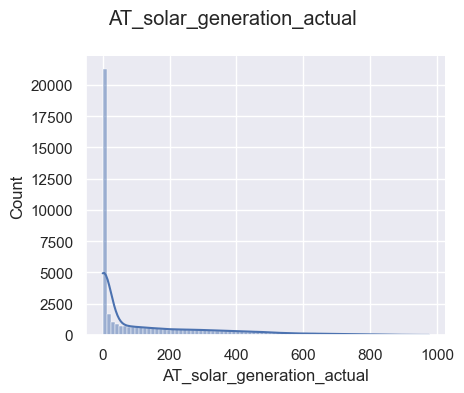

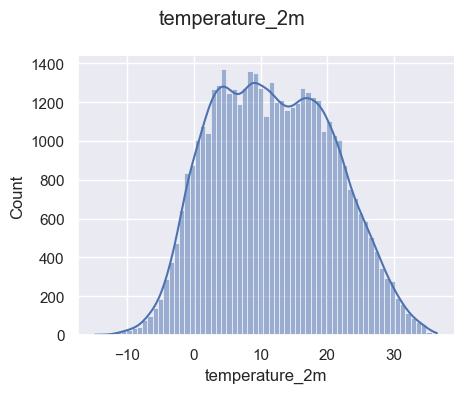

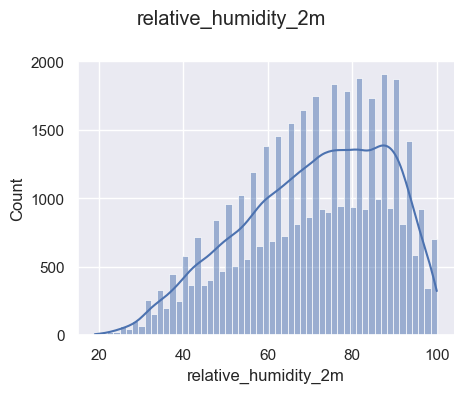

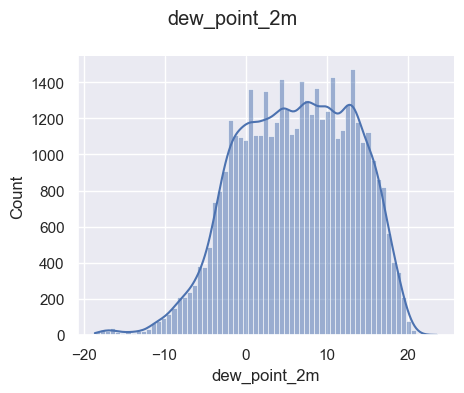

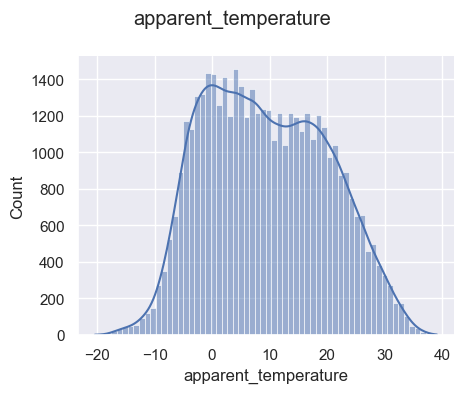

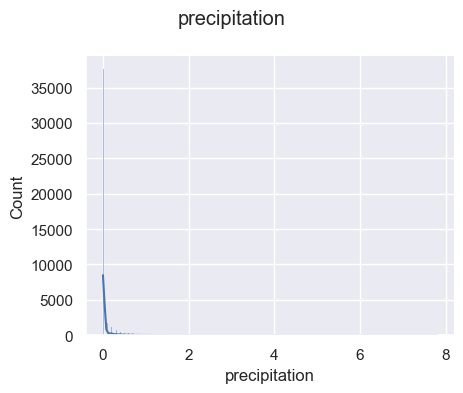

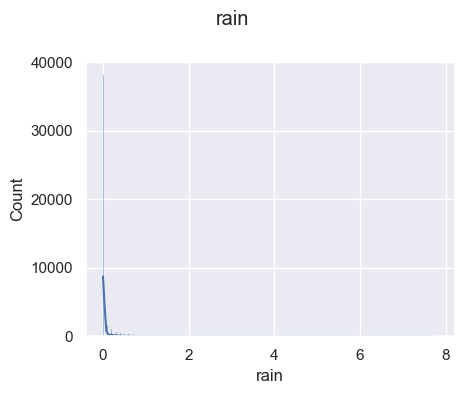

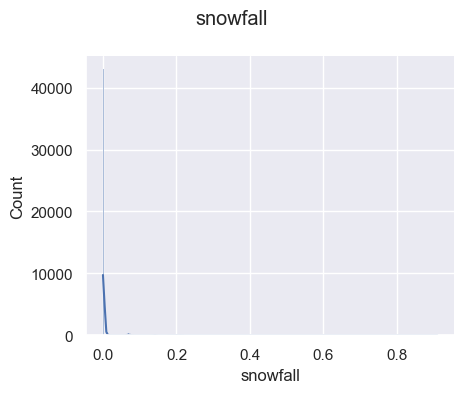

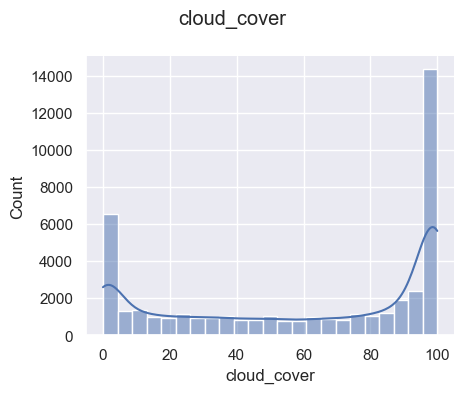

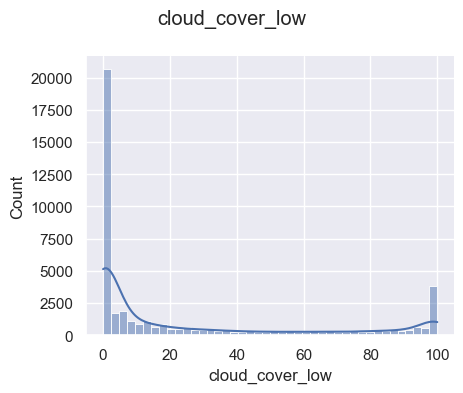

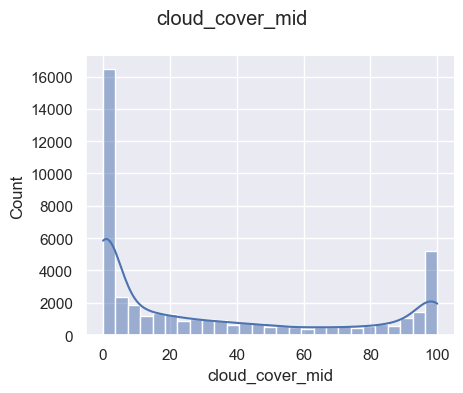

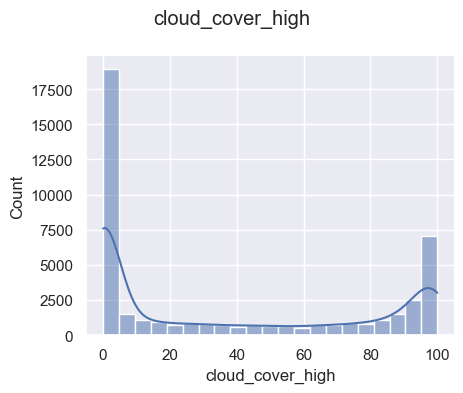

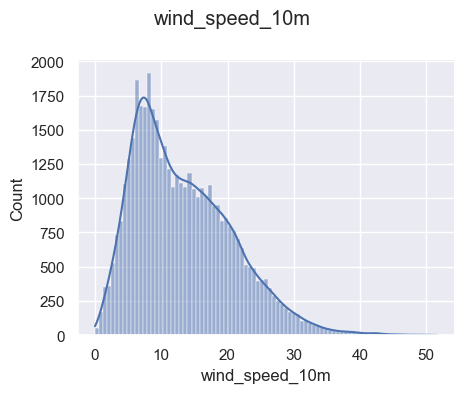

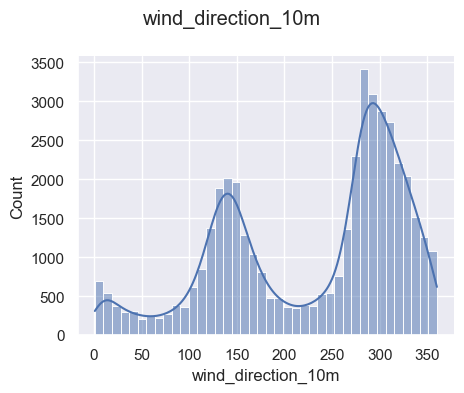

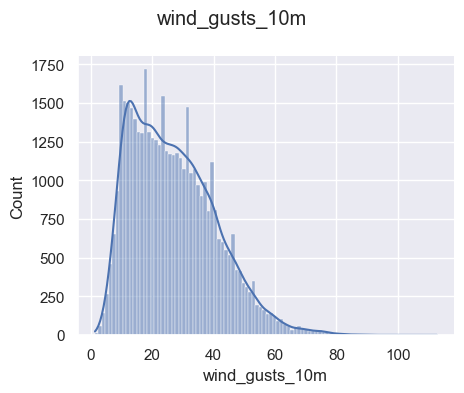

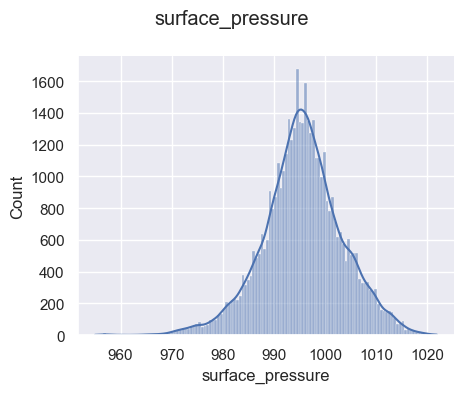

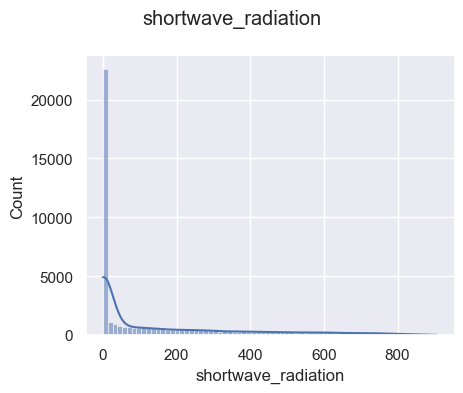

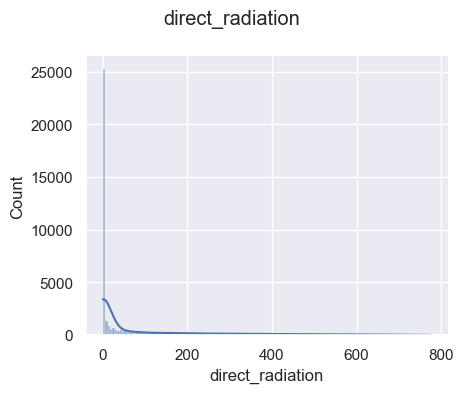

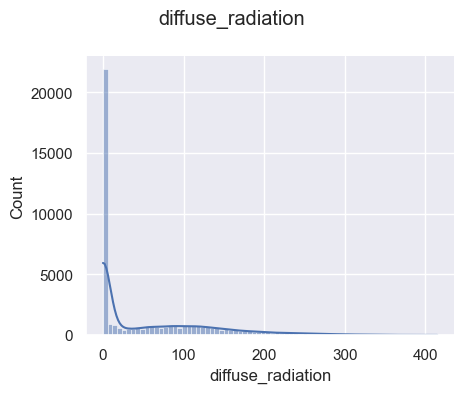

In [14]:

import os
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("plots/density", exist_ok=True)

for col in seasonsdata.columns:
    if col == "datetime":
        continue

    if not hasattr(seasonsdata[col], "dtype") or str(seasonsdata[col].dtype) == "object":
        continue

    g = sns.displot(seasonsdata[col].dropna(), kde=True, height=4, aspect=1.2)
    g.fig.suptitle(col)  # title for the whole figure
    g.fig.tight_layout()

    safe_col = str(col).replace(" ", "_").replace("/", "_").replace("\\", "_")
    g.fig.savefig(f"plots/density/density_{safe_col}.png", dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close(g.fig)



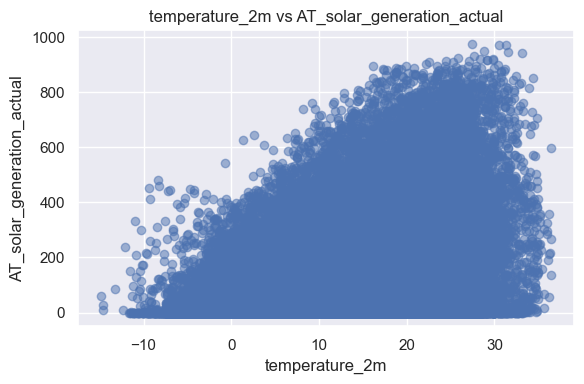

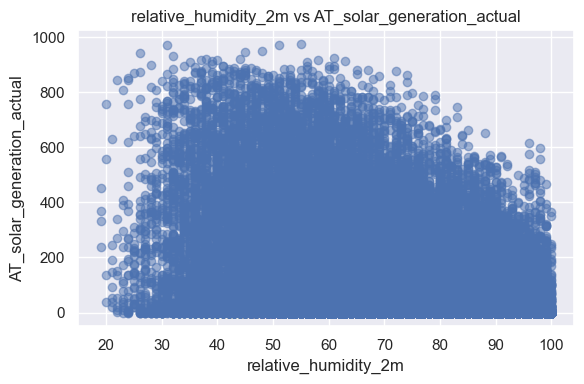

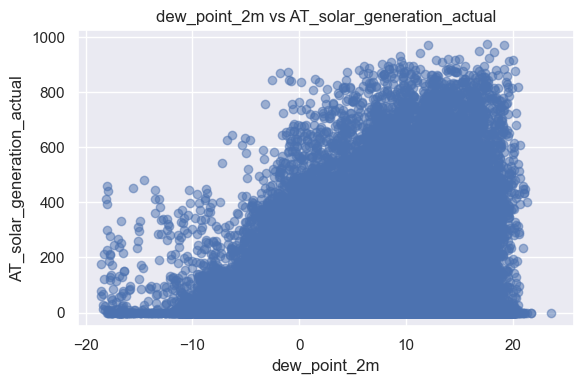

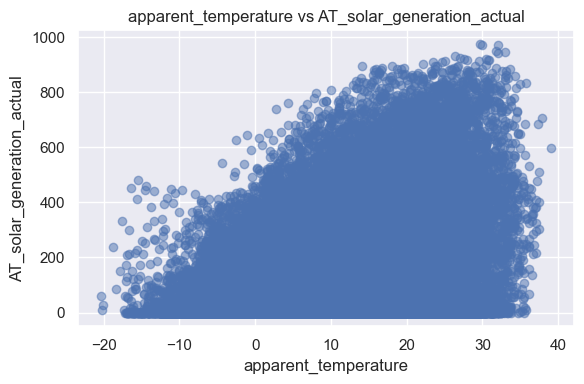

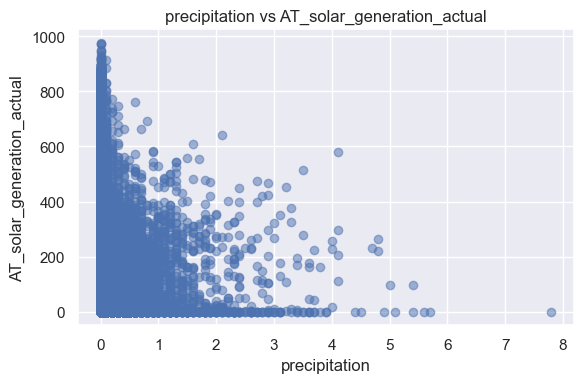

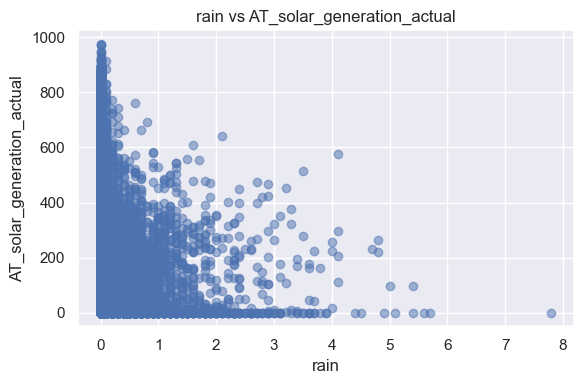

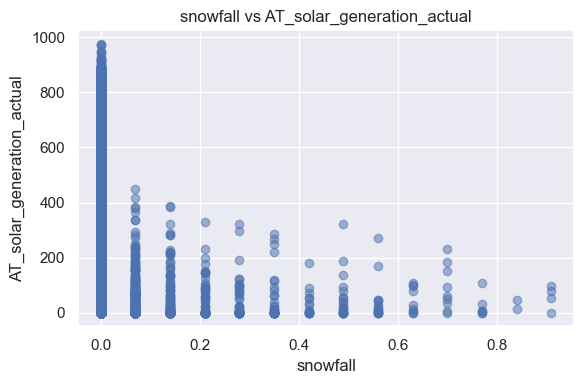

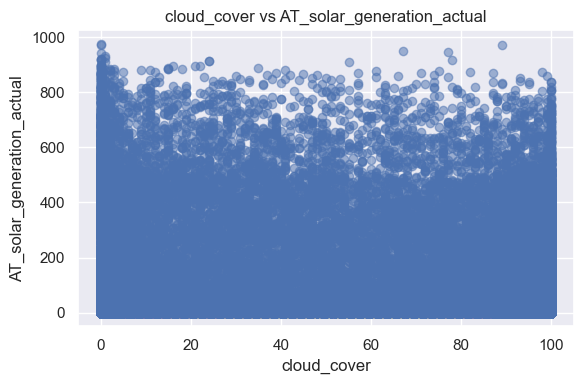

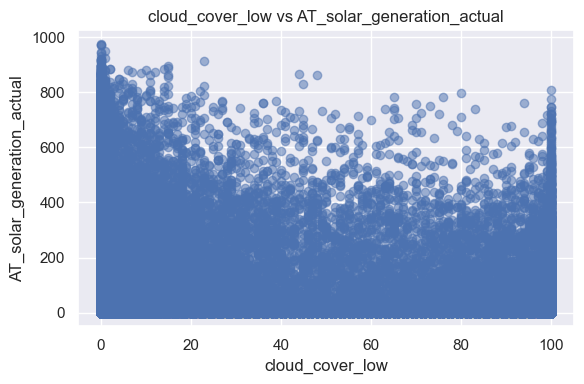

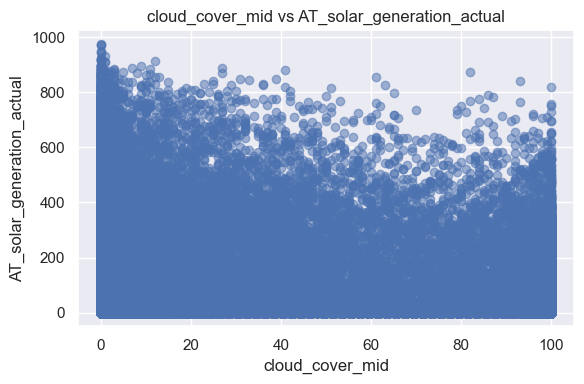

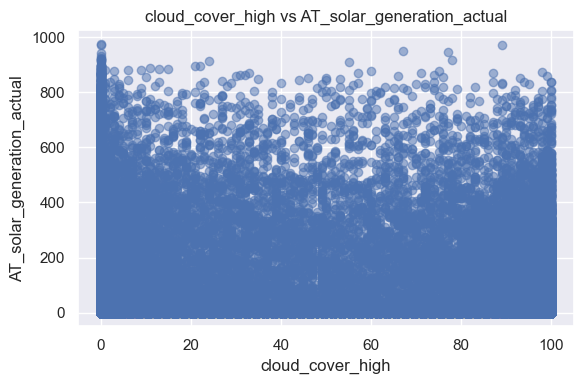

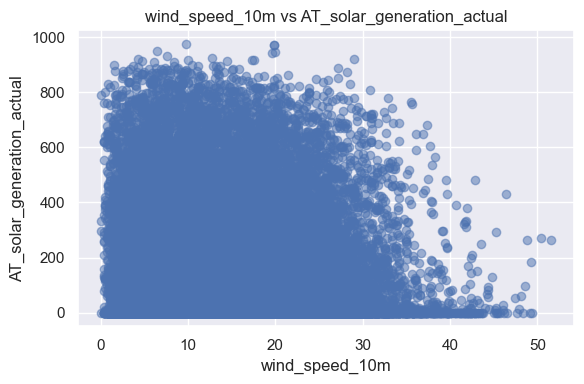

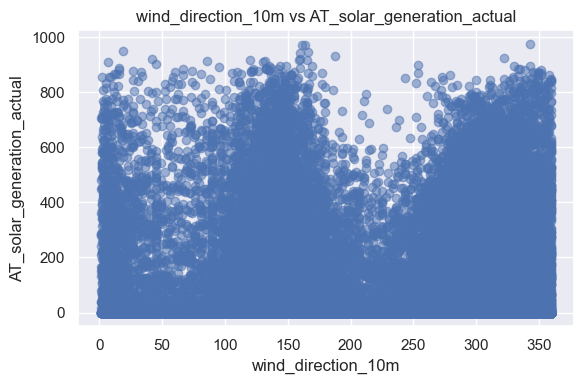

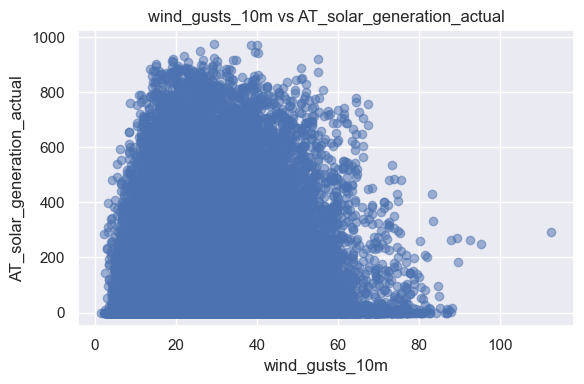

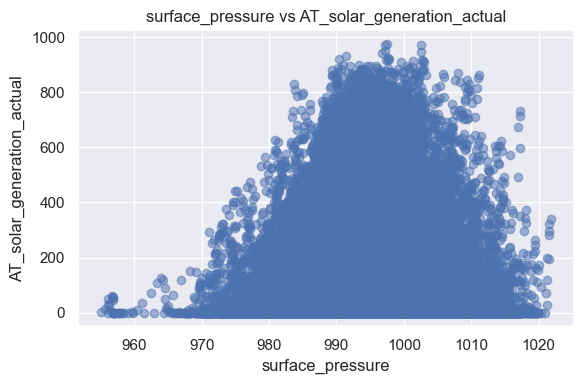

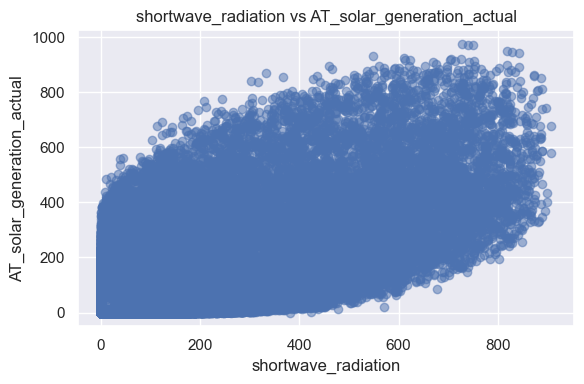

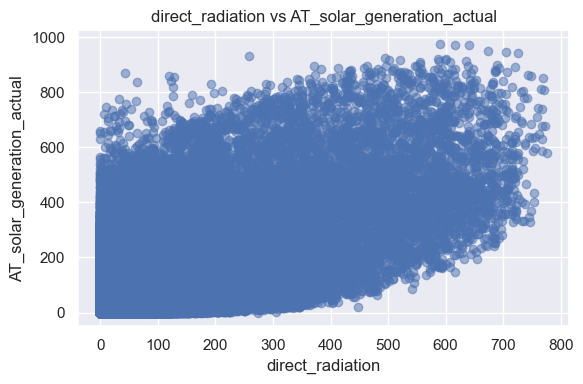

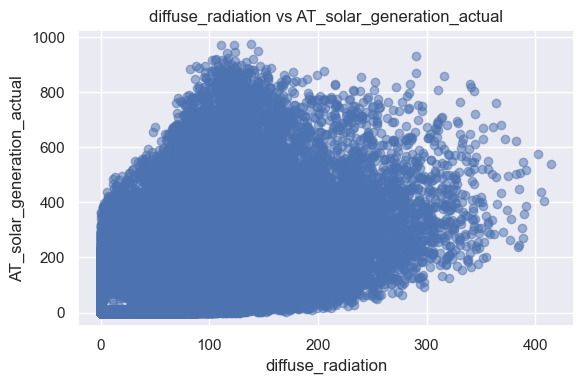

In [15]:
import os
import matplotlib.pyplot as plt

os.makedirs("plots/scatter_vs_target", exist_ok=True)

yaxis = seasonsdata['AT_solar_generation_actual']

for col in seasonsdata.columns:
    if col == 'AT_solar_generation_actual':
        continue
    if col == "datetime":
        continue

    if str(seasonsdata[col].dtype) == "object":
        continue

    xaxis = seasonsdata[col]

    plt.figure(figsize=(6,4))
    plt.scatter(xaxis, yaxis, alpha=0.5)
    plt.title(f'{col} vs AT_solar_generation_actual')
    plt.xlabel(col)
    plt.ylabel('AT_solar_generation_actual')
    plt.grid(True)
    plt.tight_layout()

    safe_col = str(col).replace(" ", "_").replace("/", "_").replace("\\", "_")
    plt.savefig(f"plots/scatter_vs_target/{safe_col}_vs_target.png",
                dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close()


## high value correlated with the Target

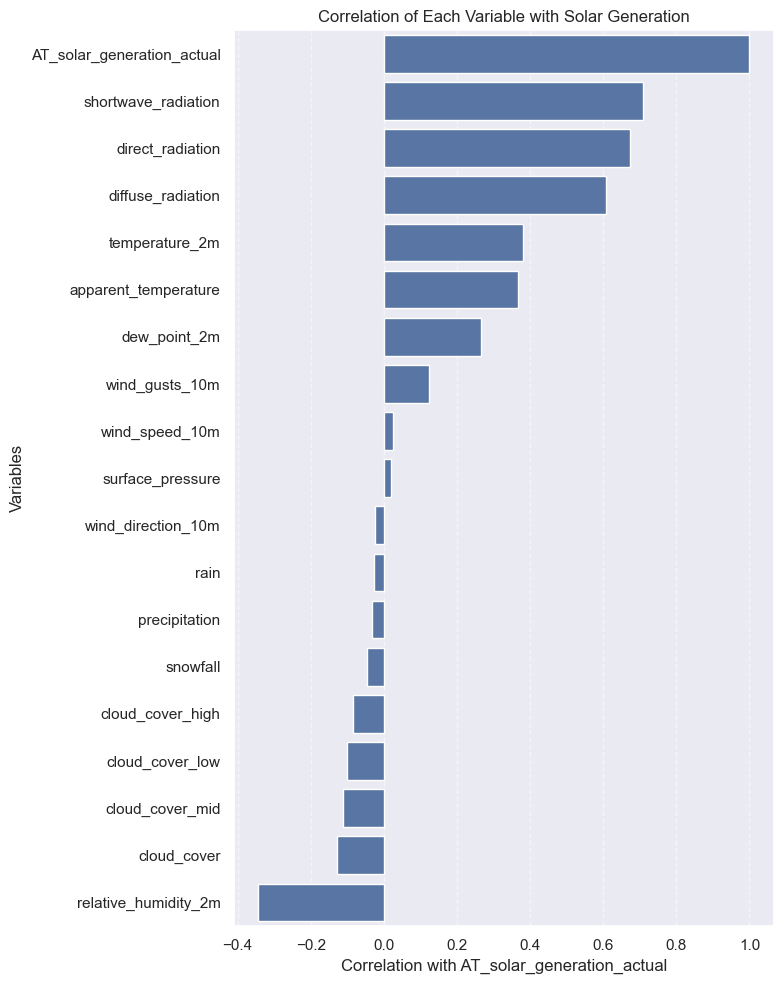

AT_solar_generation_actual    1.000000
shortwave_radiation           0.710037
direct_radiation              0.674285
diffuse_radiation             0.608568
temperature_2m                0.380039
apparent_temperature          0.368300
dew_point_2m                  0.266302
wind_gusts_10m                0.123588
wind_speed_10m                0.024472
surface_pressure              0.018674
wind_direction_10m           -0.025181
rain                         -0.025770
precipitation                -0.032636
snowfall                     -0.045301
cloud_cover_high             -0.083252
cloud_cover_low              -0.101271
cloud_cover_mid              -0.112657
cloud_cover                  -0.129076
relative_humidity_2m         -0.343148
Name: AT_solar_generation_actual, dtype: float64

In [16]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

target = "AT_solar_generation_actual"

corr = seasonsdata.corr(numeric_only=True)

corr_to_target = corr[target].sort_values(ascending=False)

plt.figure(figsize=(8, 10))
sns.barplot(x=corr_to_target.values, y=corr_to_target.index, orient='h')
plt.xlabel(f"Correlation with {target}")
plt.ylabel("Variables")
plt.title("Correlation of Each Variable with Solar Generation")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig("plots/corr_with_target_seasonsdata.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

corr_to_target


In [17]:
seasonsdata.columns

Index(['datetime', 'AT_solar_generation_actual', 'temperature_2m',
       'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature',
       'precipitation', 'rain', 'snowfall', 'cloud_cover', 'cloud_cover_low',
       'cloud_cover_mid', 'cloud_cover_high', 'wind_speed_10m',
       'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure',
       'shortwave_radiation', 'direct_radiation', 'diffuse_radiation'],
      dtype='object')

In [18]:
seasonsdata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43800 entries, 0 to 43847
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   datetime                    43800 non-null  datetime64[ns]
 1   AT_solar_generation_actual  43800 non-null  float64       
 2   temperature_2m              43800 non-null  float64       
 3   relative_humidity_2m        43800 non-null  int64         
 4   dew_point_2m                43800 non-null  float64       
 5   apparent_temperature        43800 non-null  float64       
 6   precipitation               43800 non-null  float64       
 7   rain                        43800 non-null  float64       
 8   snowfall                    43800 non-null  float64       
 9   cloud_cover                 43800 non-null  int64         
 10  cloud_cover_low             43800 non-null  int64         
 11  cloud_cover_mid             43800 non-null  int64         


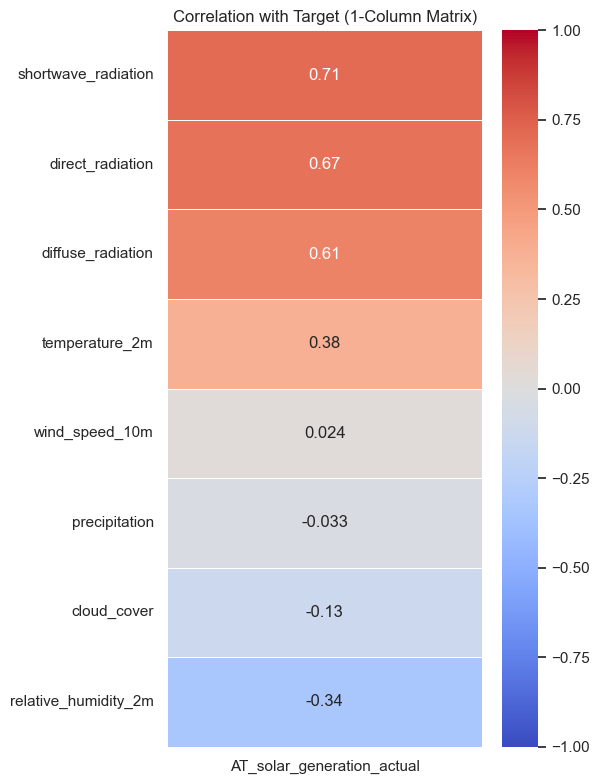

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

maincol = [
    'AT_solar_generation_actual',
    'temperature_2m',
    'relative_humidity_2m',
    'cloud_cover',
    'shortwave_radiation',
    'direct_radiation',
    'diffuse_radiation',
    'wind_speed_10m',
    'precipitation'
]

main_subset = newdata[maincol].copy()

target = "AT_solar_generation_actual"

corr_1col = (
    main_subset.corr(numeric_only=True)[[target]]
        .drop(index=target, errors="ignore")
        .sort_values(by=target, ascending=False)
)

plt.figure(figsize=(6, 8))
sns.heatmap(corr_1col, annot=True, cmap="coolwarm", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation with Target (1-Column Matrix)")
plt.tight_layout()
plt.savefig(f"corr_{target}_1col.png", dpi=1000, bbox_inches="tight")

plt.show()


In [26]:
seasonsdata['M'] = seasonsdata['datetime'].dt.month      # month
seasonsdata['D'] = seasonsdata['datetime'].dt.day        # day of month
seasonsdata['H'] = seasonsdata['datetime'].dt.hour       # hour
seasonsdata['Y'] = seasonsdata['datetime'].dt.year       # year
seasonsdata["DOY"] = seasonsdata["datetime"].dt.dayofyear # DAY OF YEAR

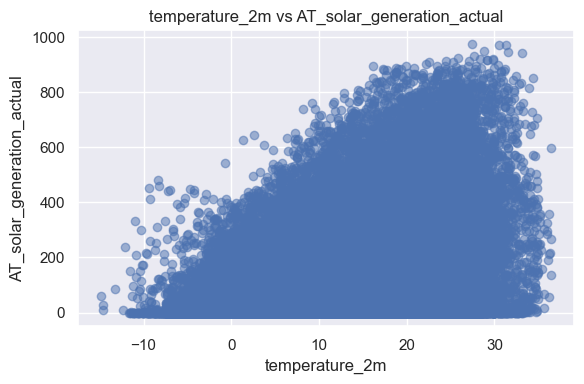

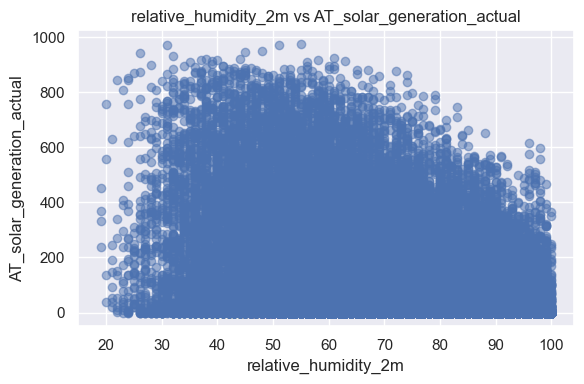

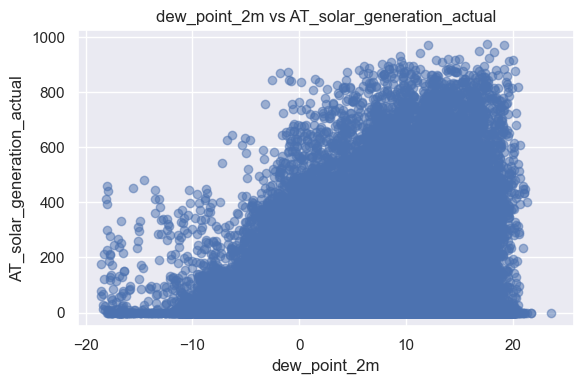

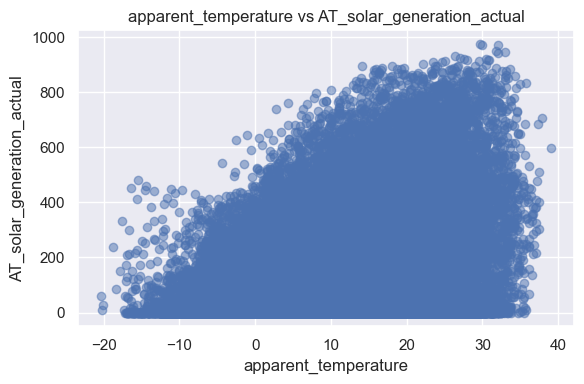

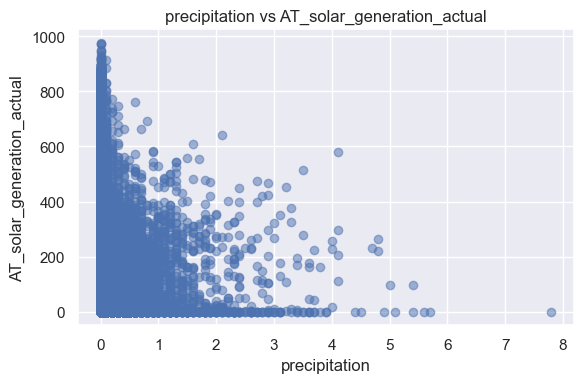

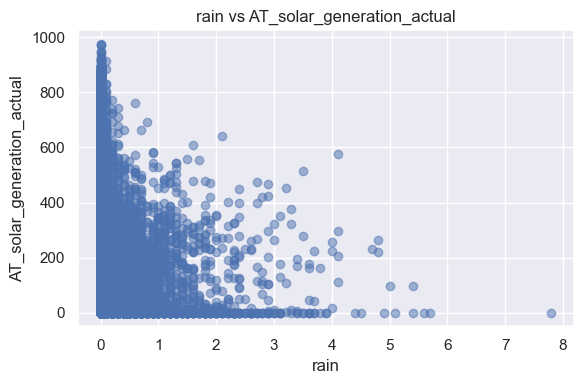

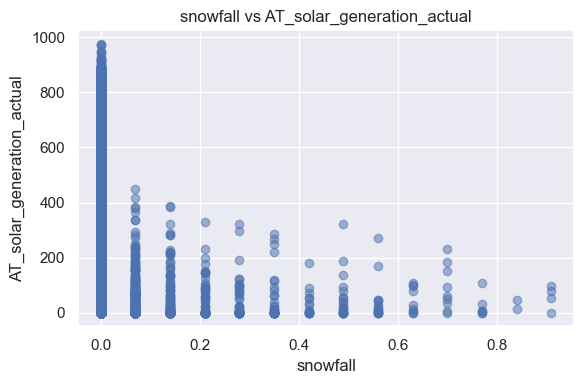

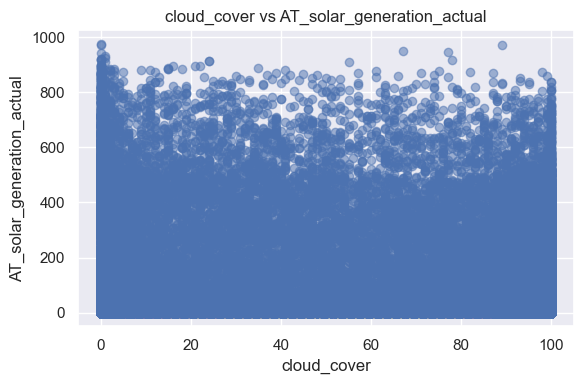

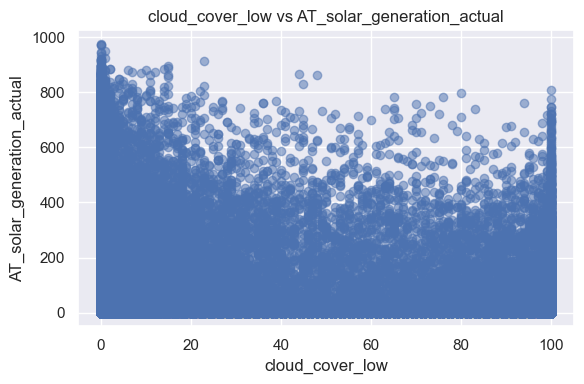

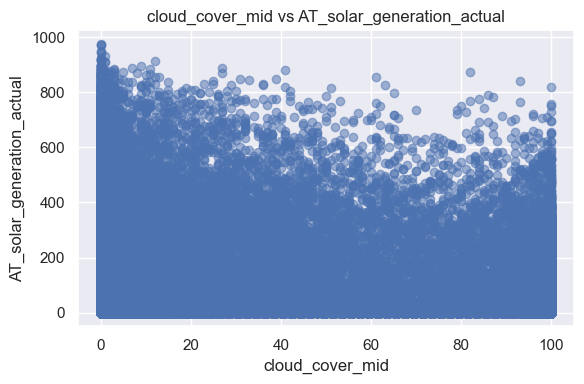

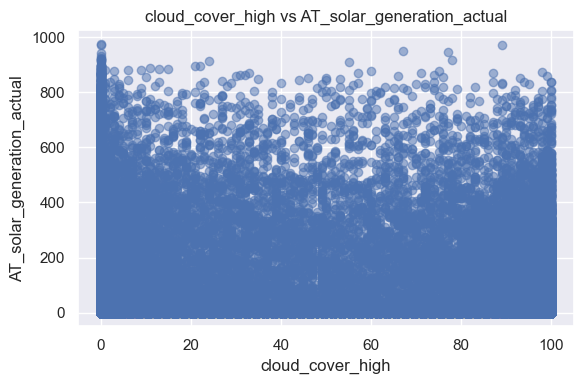

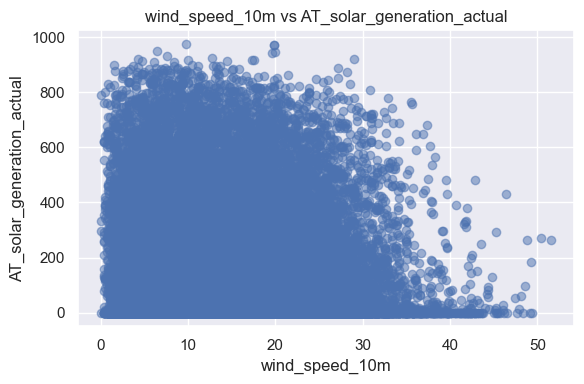

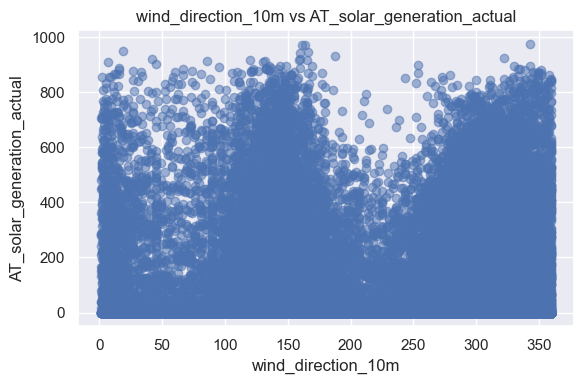

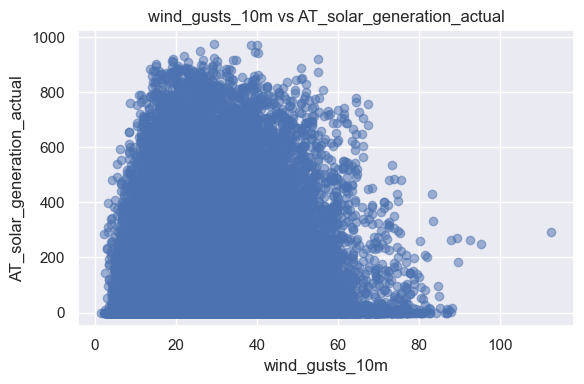

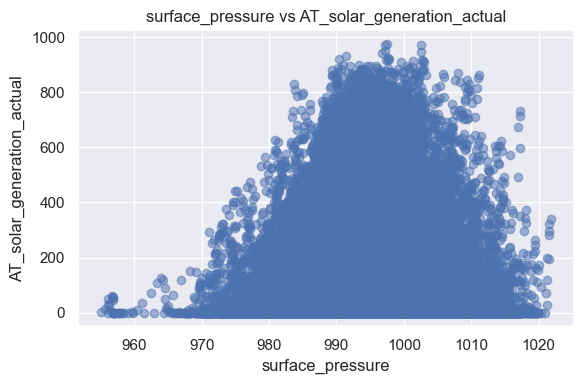

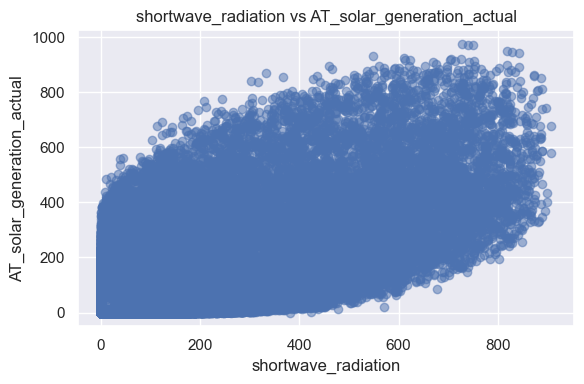

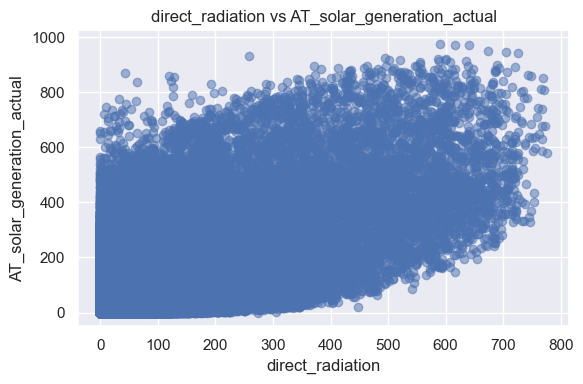

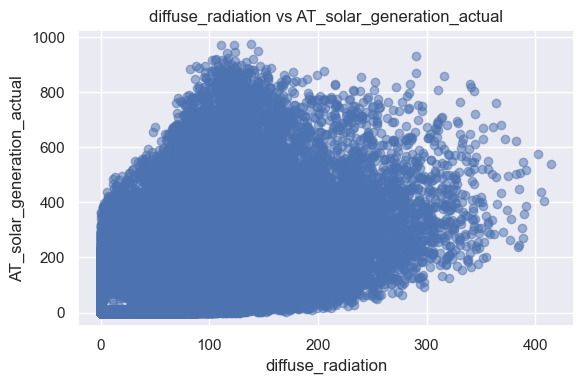

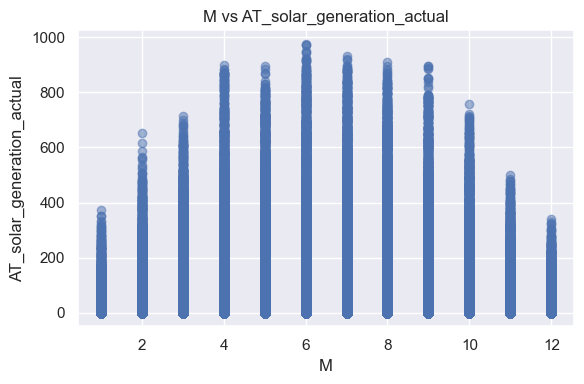

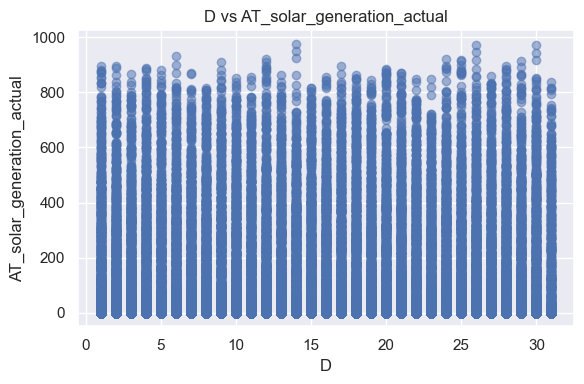

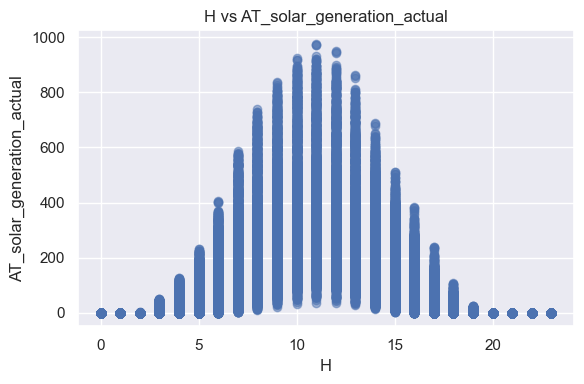

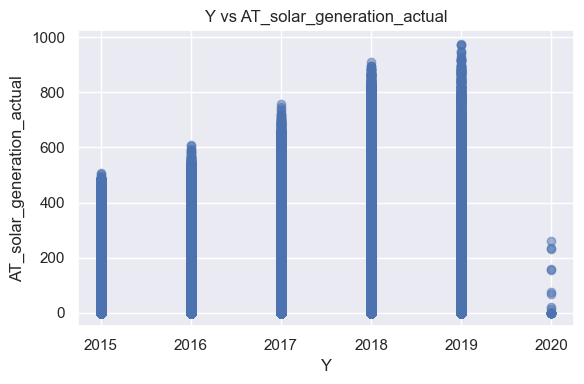

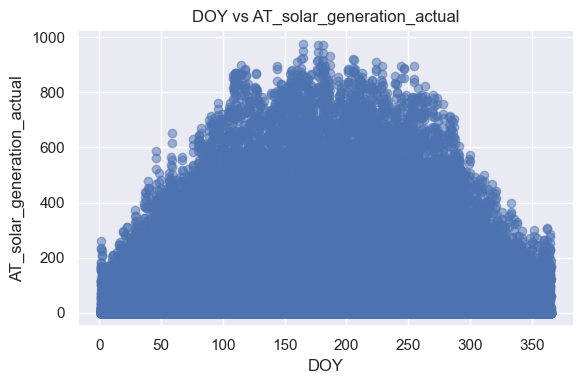

In [27]:


yaxis = seasonsdata['AT_solar_generation_actual']

for col in seasonsdata.columns:
    if col == 'AT_solar_generation_actual':
        continue
    if col == "datetime":
        continue

    if str(seasonsdata[col].dtype) == "object":
        continue

    xaxis = seasonsdata[col]

    plt.figure(figsize=(6,4))
    plt.scatter(xaxis, yaxis, alpha=0.5)
    plt.title(f'{col} vs AT_solar_generation_actual')
    plt.xlabel(col)
    plt.ylabel('AT_solar_generation_actual')
    plt.grid(True)
    plt.tight_layout()


    plt.show()


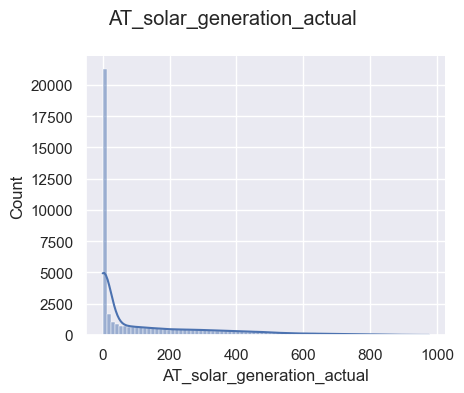

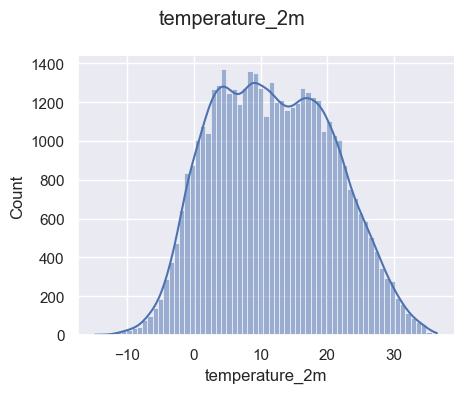

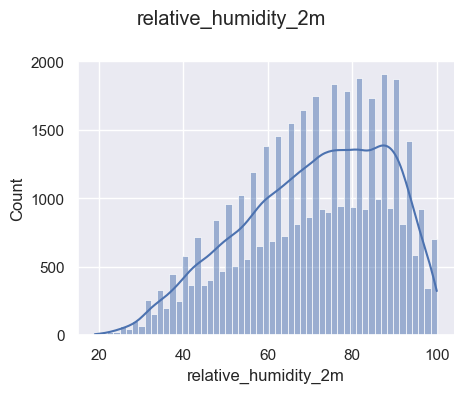

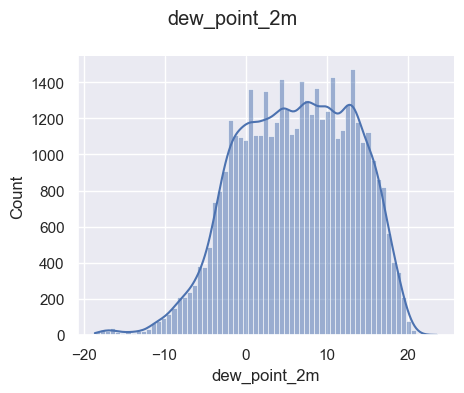

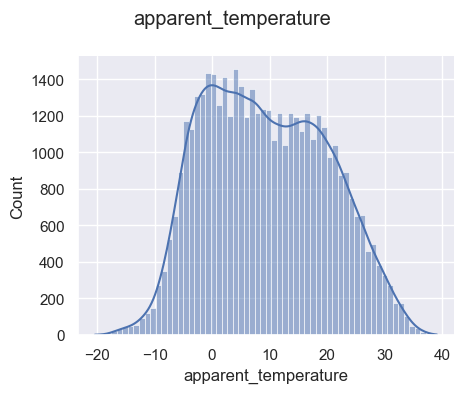

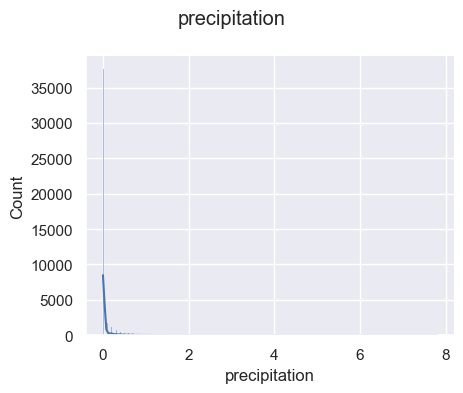

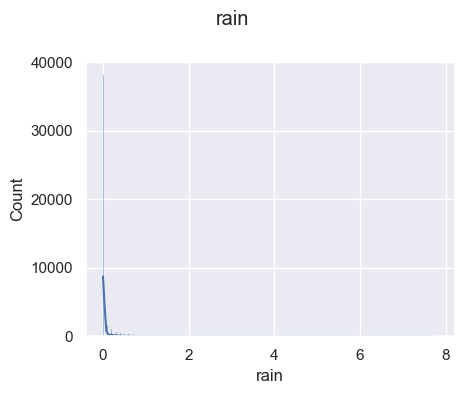

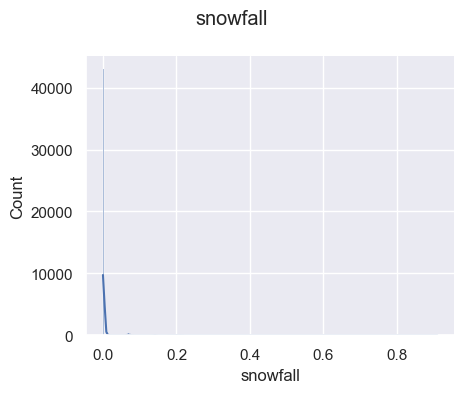

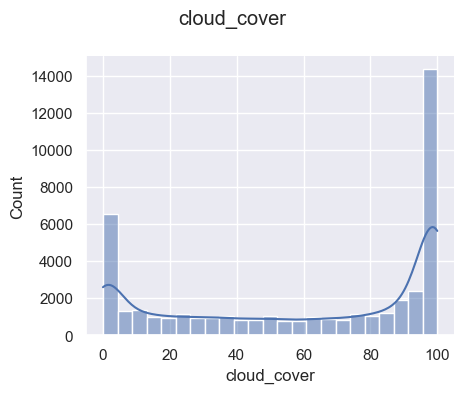

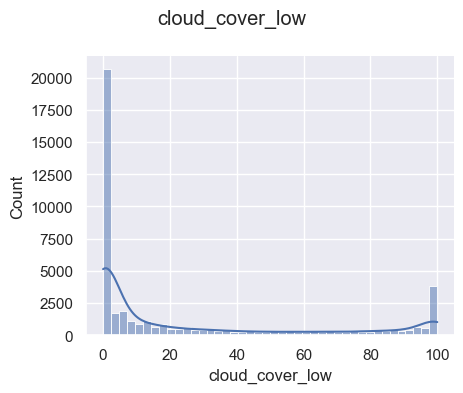

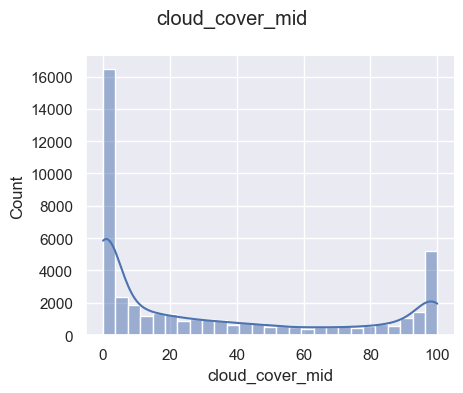

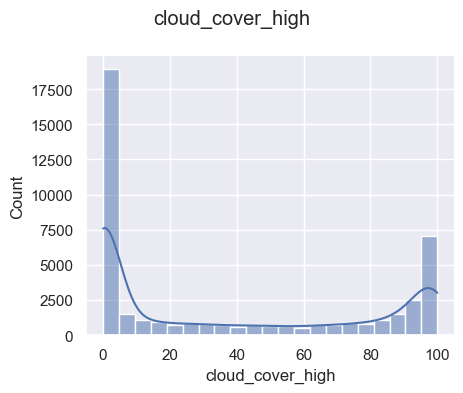

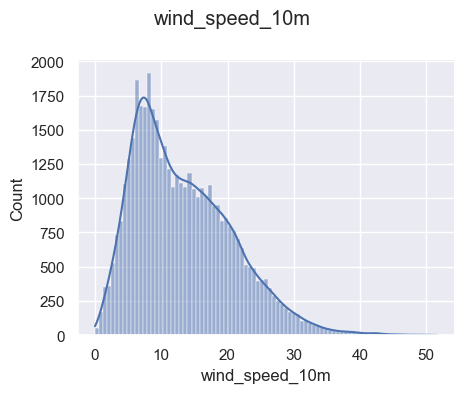

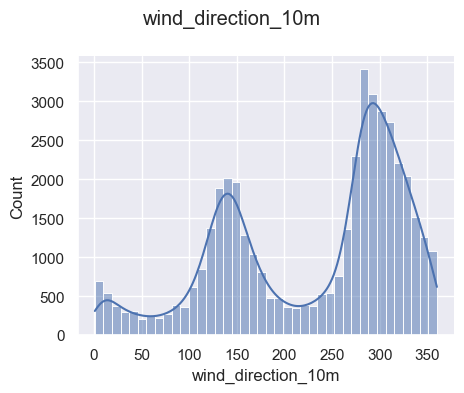

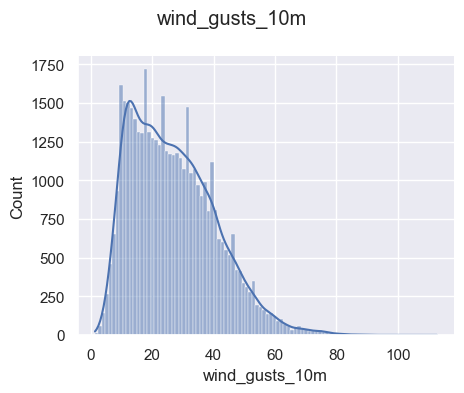

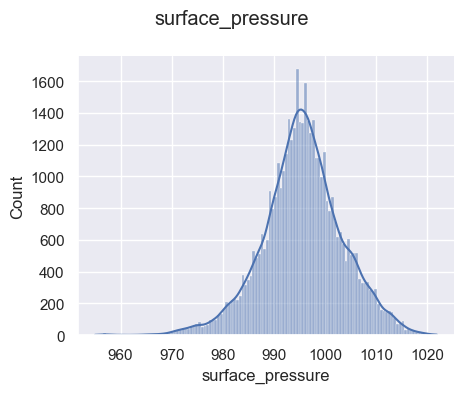

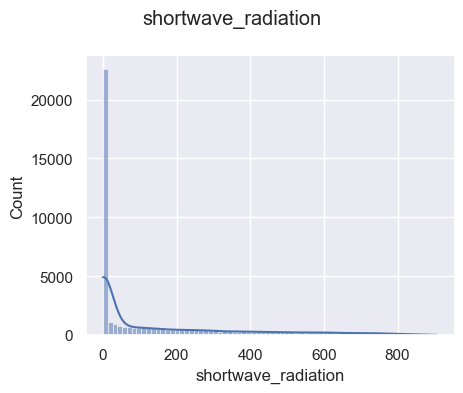

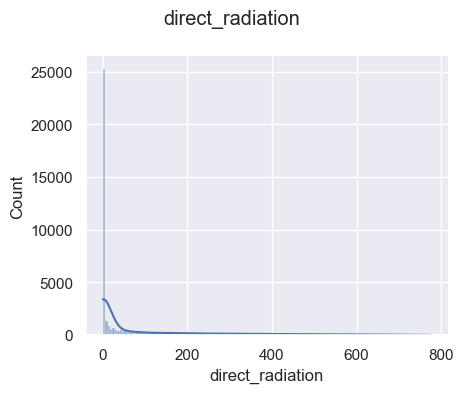

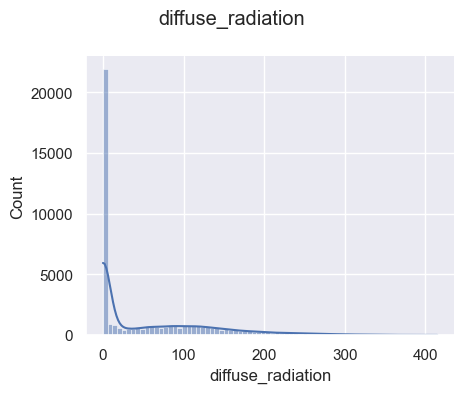

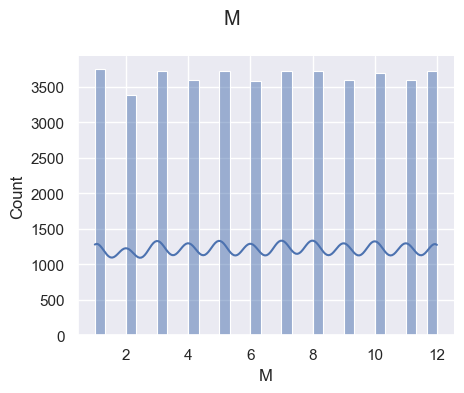

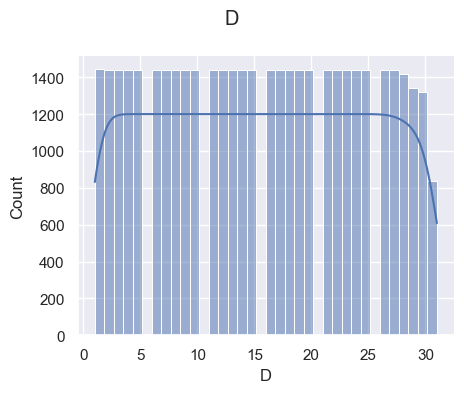

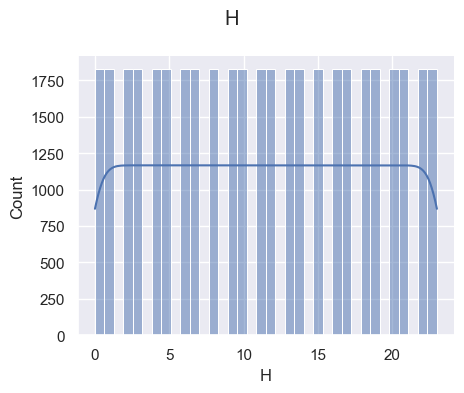

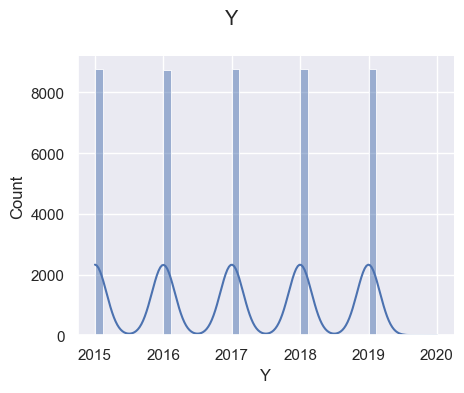

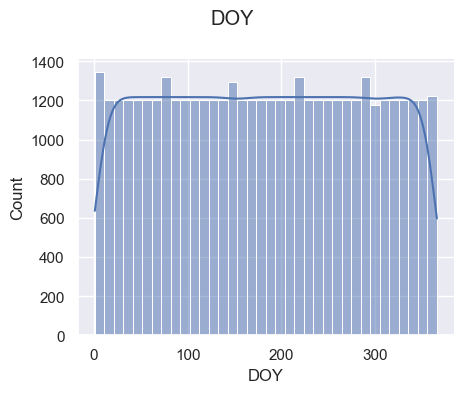

In [28]:


for col in seasonsdata.columns:
    if col == "datetime":
        continue

    if not hasattr(seasonsdata[col], "dtype") or str(seasonsdata[col].dtype) == "object":
        continue

    g = sns.displot(seasonsdata[col].dropna(), kde=True, height=4, aspect=1.2)
    g.fig.suptitle(col)  
    g.fig.tight_layout()

    safe_col = str(col).replace(" ", "_").replace("/", "_").replace("\\", "_")

    plt.show()



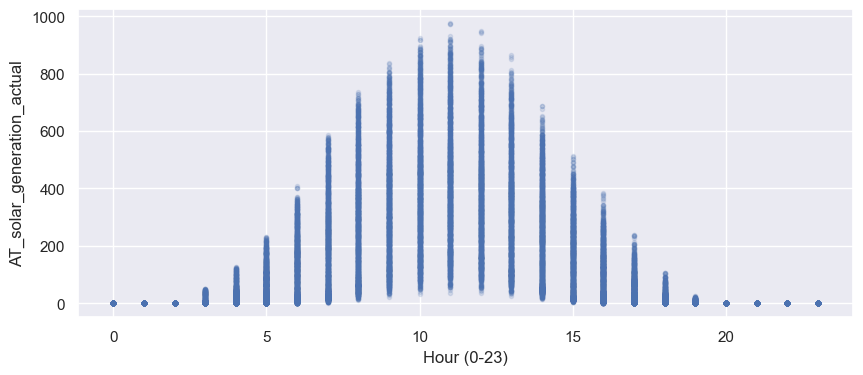

In [29]:
plt.figure(figsize=(10,4))
plt.plot(seasonsdata['H'], seasonsdata['AT_solar_generation_actual'], '.', alpha=0.15)
plt.xlabel("Hour (0-23)")
plt.ylabel("AT_solar_generation_actual")
plt.grid(True)
plt.show()


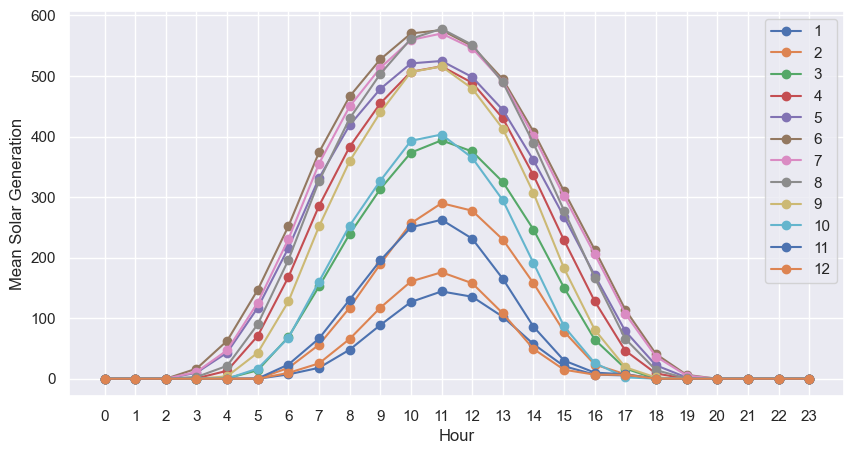

In [30]:
hourly_season = seasonsdata.groupby(['M','H'])['AT_solar_generation_actual'].mean().reset_index()

plt.figure(figsize=(10,5))
for s, g in hourly_season.groupby('M'):
    plt.plot(g['H'], g['AT_solar_generation_actual'], marker='o', linewidth=1.5, label=str(s))

plt.xticks(range(0,24))
plt.xlabel("Hour")
plt.ylabel("Mean Solar Generation")
plt.grid(True)
plt.legend()
plt.savefig(f"corr_{target}_hour vs power.png", dpi=1000, bbox_inches="tight")

plt.show()


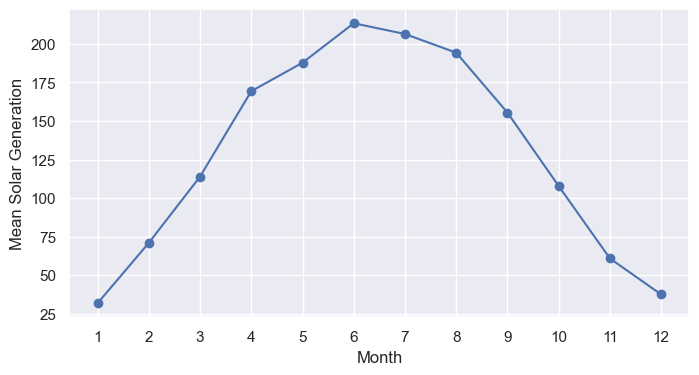

In [31]:
monthly_mean = seasonsdata.groupby('M')['AT_solar_generation_actual'].mean()

plt.figure(figsize=(8,4))
plt.plot(monthly_mean.index, monthly_mean.values, marker='o')
plt.xticks(range(1,13))
plt.xlabel("Month")
plt.ylabel("Mean Solar Generation")
plt.grid(True)
plt.savefig(f"corr_{target}_month vs power.png", dpi=1000, bbox_inches="tight")

plt.show()


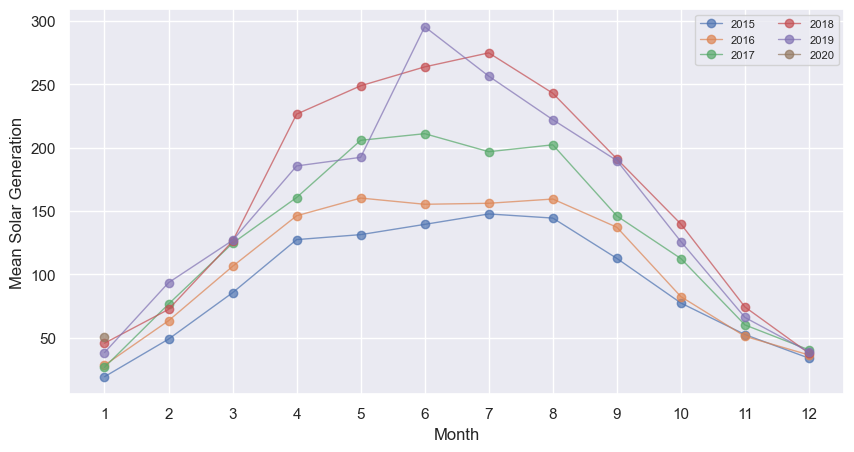

In [32]:
monthly_year = seasonsdata.groupby(['Y','M'])['AT_solar_generation_actual'].mean().reset_index()

plt.figure(figsize=(10,5))
for y, g in monthly_year.groupby('Y'):
    plt.plot(g['M'], g['AT_solar_generation_actual'], marker='o', linewidth=1, alpha=0.7, label=str(y))

plt.xticks(range(1,13))
plt.xlabel("Month")
plt.ylabel("Mean Solar Generation")
plt.grid(True)
plt.legend(ncol=2, fontsize=8)
plt.savefig(f"corr_{target}_month and year vs power.png", dpi=1000, bbox_inches="tight")

plt.show()


In [33]:
seasonsdata.to_csv("seasonsdata_cleaned.csv", index=False)
